# Retrieval-Augmented Generation (RAG) on a Domain-Specific Document Collection

**Name:** Sanskar Ramesh  Meharkar  **PRN:** 202401110029

In this notebook we build a small **RAG application**:

1. A domain-specific **document collection** (space missions: ISRO and NASA) is split into chunks.
2. Chunks and questions are converted to vectors with a **sentence-embedding model** and the closest chunks are **retrieved**.
3. A pretrained **LLM** (`Qwen/Qwen2.5-1.5B-Instruct`) generates the answer from the retrieved text.
4. The answers are **compared with the same LLM without retrieval**, using the same questions and greedy decoding.

> Use a GPU: *Runtime > Change runtime type > T4 GPU*, then *Runtime > Run all*. The last cell builds the PDF report.

## 1. Install libraries and student details

In [ ]:
!pip install -q -U transformers accelerate sentence-transformers wikipedia-api pypdf reportlab pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [ ]:
import os, re, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figs", exist_ok=True)       # figures are saved here for the PDF report
RESULTS = {}                              # every measured number is collected here

# Fill these in - they appear on the PDF report
STUDENT = dict(
    name="Sanskar Meharkar",
    prn="<your PRN>",
    batch="<your batch>",
    github="<your GitHub link>",
    colab="<your Colab link>",
)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 2. The document collection

Domain: **space missions (ISRO and NASA)**. These pages contain many specific dates, names and numbers, which a small LLM often gets wrong without the documents.

*To use your own documents instead* (PDF or TXT), create a folder `my_docs/` in Colab, upload the files into it and re-run this cell: they are added to the collection.

In [ ]:
import wikipediaapi

DOMAIN = "Space missions (ISRO and NASA), Wikipedia articles"
TITLES = ["Chandrayaan-3", "Chandrayaan-2", "Mars Orbiter Mission", "Aditya-L1",
          "James Webb Space Telescope", "Perseverance (rover)", "Artemis 1", "Gaganyaan"]
MAX_WORDS = 10000                          # keep the first part of very long pages

wiki = wikipediaapi.Wikipedia(user_agent="rag-practical/1.0 (student project)", language="en")
documents = []                             # list of dict(title, text)
for t in TITLES:
    page = wiki.page(t)
    if page.exists():
        documents.append(dict(title=t, text=" ".join(page.text.split()[:MAX_WORDS])))
    else:
        print("Page not found, skipped:", t)

# optional: your own files in my_docs/
if os.path.isdir("my_docs"):
    from pypdf import PdfReader
    for f in sorted(os.listdir("my_docs")):
        p = os.path.join("my_docs", f)
        if f.lower().endswith(".pdf"):
            txt = " ".join((pg.extract_text() or "") for pg in PdfReader(p).pages)
        elif f.lower().endswith(".txt"):
            txt = open(p, encoding="utf-8", errors="ignore").read()
        else:
            continue
        documents.append(dict(title=f, text=" ".join(txt.split()[:MAX_WORDS])))

for d in documents:
    print(f"{d['title']:32s} {len(d['text'].split()):6d} words")
RESULTS["domain"] = DOMAIN

Chandrayaan-3                      4586 words
Chandrayaan-2                      5098 words
Mars Orbiter Mission               5161 words
Aditya-L1                          3366 words
James Webb Space Telescope         9895 words
Perseverance (rover)               4475 words
Artemis 1                          4497 words
Gaganyaan                          7644 words


## 3. Split the documents into chunks

An LLM prompt can only hold a limited amount of text, and a small focused passage is easier to match to a question than a whole page. So each document is cut into chunks of **120 words with 30 words of overlap** (the overlap stops a fact from being cut in half at a boundary).

In [ ]:
CHUNK_WORDS, OVERLAP = 120, 30

def chunk_text(text, size=CHUNK_WORDS, overlap=OVERLAP):
    words = text.split()
    step = size - overlap
    return [" ".join(words[i:i + size]) for i in range(0, max(len(words) - overlap, 1), step)]

chunks = []
for d in documents:
    for c in chunk_text(d["text"]):
        chunks.append(dict(source=d["title"], text=c))

print("Documents:", len(documents), "| Chunks:", len(chunks))
RESULTS.update(chunk_words=CHUNK_WORDS, overlap=OVERLAP, n_chunks=len(chunks))
RESULTS["docs"] = [dict(title=d["title"], words=len(d["text"].split()),
                        chunks=sum(c["source"] == d["title"] for c in chunks)) for d in documents]

Documents: 8 | Chunks: 499


## 4. Embeddings and retrieval

`all-MiniLM-L6-v2` turns every chunk into a 384-number vector. The vectors are normalised, so the **dot product equals cosine similarity**. To answer a question we embed it too and take the **top-k most similar chunks**.

In [ ]:
import torch
from sentence_transformers import SentenceTransformer

EMB_ID = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMB_ID, device="cuda")
E = embedder.encode([c["text"] for c in chunks], batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
print("Chunk embedding matrix:", E.shape)

def retrieve(query, k=4):
    q = embedder.encode([query], normalize_embeddings=True)[0]
    sims = E @ q
    idx = np.argsort(-sims)[:k]
    return [dict(chunks[i], score=float(sims[i])) for i in idx]

RESULTS["embedder"] = EMB_ID

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Chunk embedding matrix: (499, 384)


## 5. Load the pretrained LLM

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tok = AutoTokenizer.from_pretrained(LLM_ID)
model = AutoModelForCausalLM.from_pretrained(LLM_ID, torch_dtype=torch.float16, device_map="cuda").eval()
print("Loaded", LLM_ID, "on", torch.cuda.get_device_name(0))
RESULTS["llm"] = LLM_ID
RESULTS["gpu"] = torch.cuda.get_device_name(0)

@torch.no_grad()
def llm(messages, max_new_tokens=200):
    # greedy decoding: the same input always gives the same output, so the two settings are comparable
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to("cuda")
    start = time.time()
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         temperature=None, top_p=None, top_k=None)
    ans = tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
    return ans, time.time() - start

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct on Tesla T4


## 6. Answer with and without retrieval

* **Without RAG:** the question is sent to the LLM alone.
* **With RAG:** the retrieved chunks are put in the prompt and the LLM is told to answer **only** from them, and to say so if the answer is not there.

In [ ]:
K = 4
RESULTS["k"] = K
NOT_FOUND = "I could not find this in the documents."

def answer_without_rag(q):
    return llm([{"role": "user", "content": q}])

def answer_with_rag(q, k=K):
    hits = retrieve(q, k)
    context = "\n\n".join(f"[{i+1}] ({h['source']}) {h['text']}" for i, h in enumerate(hits))
    messages = [
        {"role": "system", "content": "You answer questions using ONLY the context given. "
                                      f"If the answer is not in the context, reply exactly: {NOT_FOUND}"},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {q}"},
    ]
    ans, t = llm(messages)
    return ans, t, hits

_ = llm([{"role": "user", "content": "Hello"}], max_new_tokens=5)       # warm-up

# quick demo
q = "On what date did the Mars Orbiter Mission enter Mars orbit?"
a0, t0 = answer_without_rag(q)
a1, t1, hits = answer_with_rag(q)
print("QUESTION:", q)
print("\nWITHOUT RAG:", a0)
print("\nWITH RAG   :", a1)
print("\nRetrieved chunks:")
for h in hits:
    print(f"  {h['score']:.2f}  [{h['source']}]  {h['text'][:110]}...")

QUESTION: On what date did the Mars Orbiter Mission enter Mars orbit?

WITHOUT RAG: The Mars Orbiter Mission (MOM) entered Mars orbit on September 24, 2013. This was a significant milestone in India's space program and marked the first time an Indian spacecraft had orbited another planet. The mission was launched from Sriharikota, Andhra Pradesh, on November 5, 2013, and it successfully completed its primary objectives of studying the Martian atmosphere and surface features.

WITH RAG   : The Mars Orbiter Mission entered Mars orbit on 30 November 2013 (UTC).

Retrieved chunks:
  0.59  [Mars Orbiter Mission]  do so with an indigenously developed propulsion system and the second national space agency to succeed on its ...
  0.57  [Mars Orbiter Mission]  orbit around Mars. ISRO extended the mission by an additional six months; the spacecraft has 37 kg (82 lb) of ...
  0.56  [Mars Orbiter Mission]  Mars. Very few full disk images have ever been taken in the past, mostly on approach to the 

## 7. Evaluation set

Nine questions whose answers are in the documents (each has **expected key facts**) and two questions that the documents **cannot** answer (the correct behaviour is to say so).
The **keyword score** is the fraction of the expected facts that appear in the answer. `a|b` means either wording is accepted.
> The expected facts were written from general knowledge. Check them against the Wikipedia pages if you change the documents.

In [ ]:
eval_set = [
 dict(q="When did the Chandrayaan-3 lander touch down on the Moon, and near which region?",
      keys=["23 august 2023|august 23, 2023", "south pole|south polar"]),
 dict(q="On what date did the Mars Orbiter Mission enter Mars orbit?",
      keys=["24 september 2014|september 24, 2014"]),
 dict(q="What is the diameter of the James Webb Space Telescope's primary mirror and how many segments does it have?",
      keys=["6.5", "18"]),
 dict(q="Which Lagrange point is Aditya-L1 placed at?",
      keys=["l1"]),
 dict(q="In which crater did the Perseverance rover land?",
      keys=["jezero"]),
 dict(q="What are the names of the Chandrayaan-3 lander and rover?",
      keys=["vikram", "pragyan"]),
 dict(q="On what date did Artemis 1 launch?",
      keys=["16 november 2022|november 16, 2022"]),
 dict(q="Which launch vehicle was used for Chandrayaan-3?",
      keys=["lvm3|lvm 3|gslv mk iii|gslv mark iii|gslv mk 3"]),
 dict(q="On what date was the James Webb Space Telescope launched?",
      keys=["25 december 2021|december 25, 2021"]),
]
unanswerable = [
 "Who won the FIFA World Cup in 2022?",
 "Which Indian astronaut walked on the surface of the Moon?",
]

def keyword_score(text, keys):
    t = text.lower()
    return sum(any(alt.strip() in t for alt in k.split("|")) for k in keys) / len(keys)

def abstained(text):
    t = text.lower()
    return any(p in t for p in ["could not find", "cannot find", "can't find", "not mentioned", "no information",
                                "don't know", "do not know", "not provided", "not in the"])

## 8. Run the comparison

In [ ]:
rows = []
for e in eval_set:
    a0, t0 = answer_without_rag(e["q"])
    a1, t1, hits = answer_with_rag(e["q"])
    ctx = " ".join(h["text"] for h in hits)
    rows.append(dict(type="answerable", question=e["q"], answer_no=a0, answer_rag=a1,
                     score_no=keyword_score(a0, e["keys"]), score_rag=keyword_score(a1, e["keys"]),
                     retrieval_hit=keyword_score(ctx, e["keys"]), time_no=t0, time_rag=t1,
                     sources=[h["source"] for h in hits], abstain_no=None, abstain_rag=None))
for q in unanswerable:
    a0, t0 = answer_without_rag(q)
    a1, t1, hits = answer_with_rag(q)
    rows.append(dict(type="unanswerable", question=q, answer_no=a0, answer_rag=a1,
                     score_no=None, score_rag=None, retrieval_hit=None, time_no=t0, time_rag=t1,
                     sources=[h["source"] for h in hits], abstain_no=abstained(a0), abstain_rag=abstained(a1)))
RESULTS["rows"] = rows
RESULTS["example_retrieval"] = retrieve(eval_set[0]["q"], K)

df = pd.DataFrame([r for r in rows if r["type"] == "answerable"])
print(df[["question", "score_no", "score_rag", "retrieval_hit"]].to_string(index=False))
print("\nMean keyword score  without RAG: %.2f   with RAG: %.2f" % (df.score_no.mean(), df.score_rag.mean()))
print("Mean retrieval hit: %.2f" % df.retrieval_hit.mean())

                                                                                                   question  score_no  score_rag  retrieval_hit
                           When did the Chandrayaan-3 lander touch down on the Moon, and near which region?       0.0        1.0            1.0
                                                On what date did the Mars Orbiter Mission enter Mars orbit?       0.0        0.0            0.0
What is the diameter of the James Webb Space Telescope's primary mirror and how many segments does it have?       1.0        1.0            1.0
                                                               Which Lagrange point is Aditya-L1 placed at?       1.0        1.0            1.0
                                                           In which crater did the Perseverance rover land?       1.0        1.0            1.0
                                                  What are the names of the Chandrayaan-3 lander and rover?       0.5        0.5        

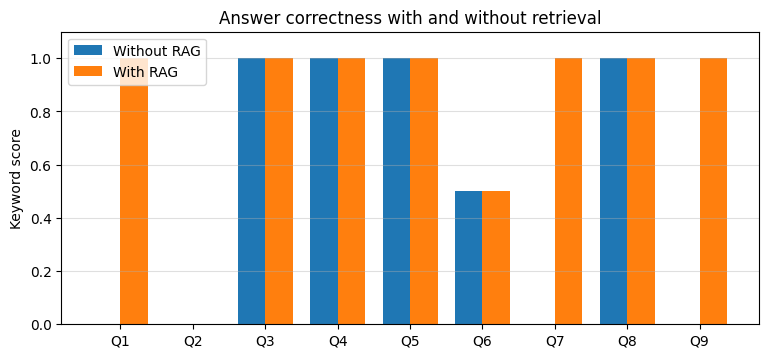

In [ ]:
# Figure: keyword score per question
x = np.arange(len(df)); w = 0.38
plt.figure(figsize=(9, 3.8))
plt.bar(x - w/2, df.score_no, w, label="Without RAG")
plt.bar(x + w/2, df.score_rag, w, label="With RAG")
plt.xticks(x, [f"Q{i+1}" for i in x]); plt.ylim(0, 1.1)
plt.ylabel("Keyword score"); plt.title("Answer correctness with and without retrieval")
plt.legend(); plt.grid(axis="y", alpha=.4)
plt.savefig("figs/scores.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Read the answers side by side

In [ ]:
for i, r in enumerate(rows):
    print(f"Q{i+1} [{r['type']}] {r['question']}")
    print("   WITHOUT RAG:", r["answer_no"][:350].replace("\n", " "))
    print("   WITH RAG   :", r["answer_rag"][:350].replace("\n", " "))
    print("   sources    :", sorted(set(r["sources"])))
    print()

Q1 [answerable] When did the Chandrayaan-3 lander touch down on the Moon, and near which region?
   WITHOUT RAG: The Chandrayaan-3 lander touched down on the Moon on September 24, 2023, in the Sinus Iridum (the Bay of Rainbows) region. This landing marked the successful completion of India's third mission to the Moon, following Chandrayaan-1 and Chandrayaan-2. The spacecraft was designed to study the lunar surface composition, geology, and potential water ice
   WITH RAG   : The Chandrayaan-3 lander touched down on the Moon on August 23, 2023, near the lunar south pole.
   sources    : ['Chandrayaan-2', 'Chandrayaan-3']

Q2 [answerable] On what date did the Mars Orbiter Mission enter Mars orbit?
   WITHOUT RAG: The Mars Orbiter Mission (MOM) entered Mars orbit on September 24, 2013. This was a significant milestone in India's space program and marked the first time an Indian spacecraft had orbited another planet. The mission was launched from Sriharikota, Andhra Pradesh, on November 5,

In [ ]:
# Questions the documents cannot answer: does the model say so?
for r in rows:
    if r["type"] == "unanswerable":
        print(r["question"])
        print("   declined without RAG:", r["abstain_no"], "| declined with RAG:", r["abstain_rag"])

Who won the FIFA World Cup in 2022?
   declined without RAG: False | declined with RAG: True
Which Indian astronaut walked on the surface of the Moon?
   declined without RAG: False | declined with RAG: False


## 10. Effect of the number of retrieved chunks (k)

k = 1: mean keyword score = 0.56
k = 2: mean keyword score = 0.56
k = 4: mean keyword score = 0.83
k = 6: mean keyword score = 0.83


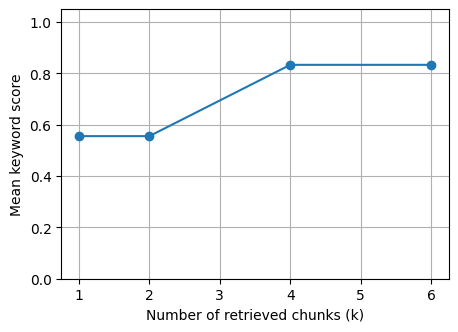

In [ ]:
ks = [1, 2, 4, 6]
k_scores = []
for k in ks:
    sc = []
    for e in eval_set:
        a, _, _ = answer_with_rag(e["q"], k=k)
        sc.append(keyword_score(a, e["keys"]))
    k_scores.append(float(np.mean(sc)))
    print(f"k = {k}: mean keyword score = {k_scores[-1]:.2f}")

RESULTS["k_ablation"] = dict(k=ks, score=k_scores)
plt.figure(figsize=(5, 3.5)); plt.plot(ks, k_scores, marker="o")
plt.xlabel("Number of retrieved chunks (k)"); plt.ylabel("Mean keyword score"); plt.ylim(0, 1.05); plt.grid(True)
plt.savefig("figs/k_ablation.png", dpi=120, bbox_inches="tight"); plt.show()
json.dump(RESULTS, open("results.json", "w"), indent=1, default=str)

## 11. Observations

After running the cells above, compare the printed answers in section 9 with the scores and write your observations here. Points to look at:

* Which questions did the plain LLM get wrong or invent details for, and did RAG fix them?
* Was there any question where RAG failed? Check the **retrieval hit**: if it is low, the right chunk was not retrieved; if it is high but the score is low, the LLM misused the context.
* Did the model decline the two questions that the documents cannot answer, with and without retrieval?
* How did the score change with k, and what happened to the answer time?

## 12. Conclusion

* A RAG application has two parts: a **retriever** (chunking, embeddings, similarity search) and a **generator** (the LLM prompted with the retrieved text).
* The answers can be traced to their source chunks, so they can be checked.
* RAG depends on retrieval quality. If the right chunk is missing, the LLM cannot answer from it.
* Telling the LLM to answer only from the context lets it decline questions that the documents cannot answer.
* The cost of RAG is a longer prompt and so a slightly longer answer time.